<a href="https://colab.research.google.com/github/Ophelie4/pfizer-document-intelligence/blob/main/project-02-python-for-document-processing/notebooks/Ophelie_Image_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Enhance a Scanned Document Using Preprocessing

Downloads `noisy_image_sample.jpg`, applies denoising, contrast enhancement, and thresholding with OpenCV/PIL, displays before/after, and saves the cleaned result.

**Setup:** install/import libraries and download the source image directly from the shared Drive link.

In [ ]:
!pip install -q opencv-python-headless gdown
import cv2
import numpy as np
from matplotlib import pyplot as plt
import gdown

In [ ]:
# Download the noisy image provided for this task
file_id = '1AaFhSPfh4TUR1EiAInNCu5nOoZ0DAO_9'
gdown.download(f'https://drive.google.com/uc?id={file_id}', 'noisy_image_sample.jpg', quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1AaFhSPfh4TUR1EiAInNCu5nOoZ0DAO_9
To: /content/noisy_image_sample.jpg
100%|██████████| 39.7k/39.7k [00:00<00:00, 36.8MB/s]


'noisy_image_sample.jpg'

## Load and inspect the original image

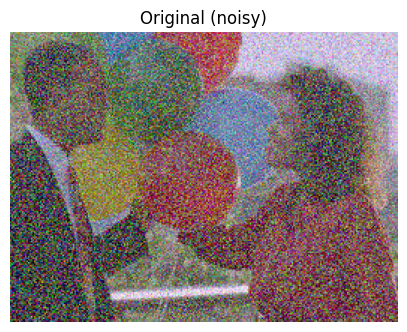

Shape: (194, 259, 3)


In [ ]:
img = cv2.imread('noisy_image_sample.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(5,4))
plt.imshow(img_rgb)
plt.title('Original (noisy)')
plt.axis('off')
plt.show()
print('Shape:', img.shape)

## Step 1 — Denoising

`cv2.fastNlMeansDenoisingColored()` removes the speckle/Gaussian-style noise visible across the image while preserving edges better than a simple blur.

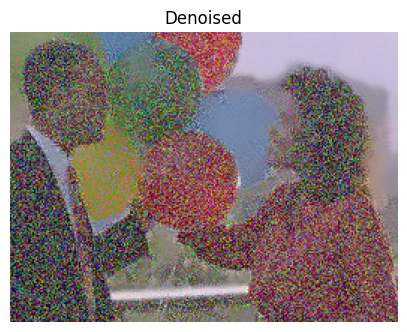

In [ ]:
denoised = cv2.fastNlMeansDenoisingColored(img, None, h=10, hColor=10, templateWindowSize=7, searchWindowSize=21)
plt.figure(figsize=(5,4))
plt.imshow(cv2.cvtColor(denoised, cv2.COLOR_BGR2RGB))
plt.title('Denoised')
plt.axis('off')
plt.show()

## Step 2 — Contrast enhancement (CLAHE)

Convert to LAB color space and apply CLAHE (Contrast Limited Adaptive Histogram Equalization) to the lightness channel only, so contrast improves without distorting color balance.

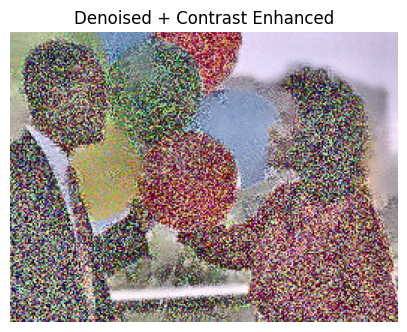

In [ ]:
lab = cv2.cvtColor(denoised, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
l_eq = clahe.apply(l)
lab_eq = cv2.merge((l_eq, a, b))
contrast_enhanced = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)
plt.figure(figsize=(5,4))
plt.imshow(cv2.cvtColor(contrast_enhanced, cv2.COLOR_BGR2RGB))
plt.title('Denoised + Contrast Enhanced')
plt.axis('off')
plt.show()

## Step 3 — Thresholding

Convert to grayscale and apply Otsu's thresholding to produce a clean binary image — this is the standard final step before OCR on a text document. (Note: since this sample happens to be a busy color photo rather than scanned text, full binarization loses most visual content here; on an actual text-based scan, this step is where the biggest OCR accuracy gains come from.)

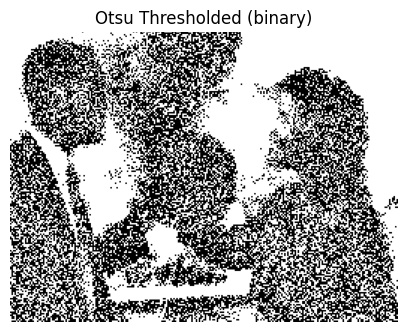

In [ ]:
gray = cv2.cvtColor(contrast_enhanced, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.figure(figsize=(5,4))
plt.imshow(binary, cmap='gray')
plt.title('Otsu Thresholded (binary)')
plt.axis('off')
plt.show()

## Before / after comparison

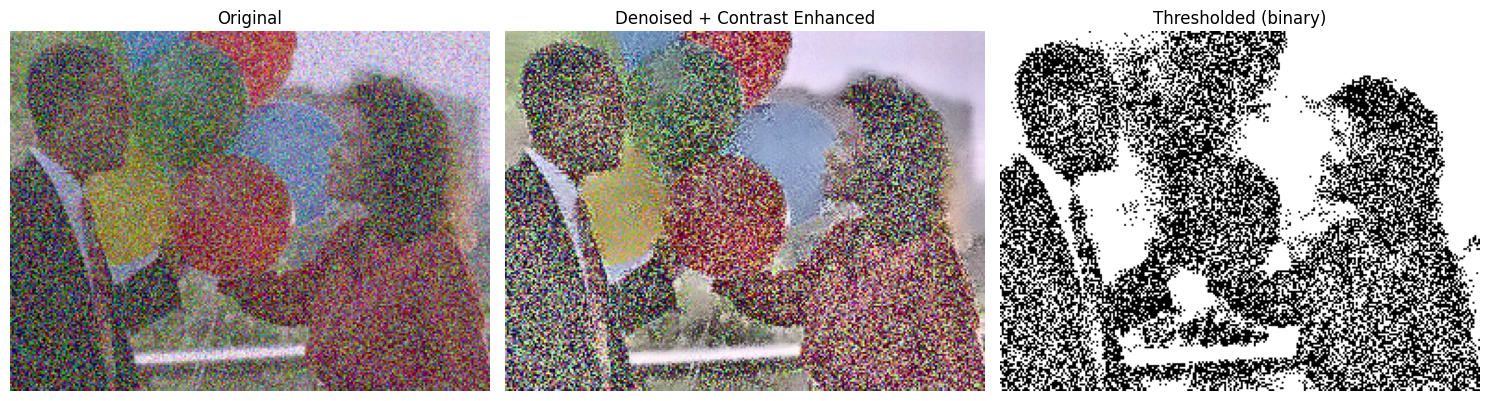

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))
axes[0].imshow(img_rgb); axes[0].set_title('Original'); axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(contrast_enhanced, cv2.COLOR_BGR2RGB)); axes[1].set_title('Denoised + Contrast Enhanced'); axes[1].axis('off')
axes[2].imshow(binary, cmap='gray'); axes[2].set_title('Thresholded (binary)'); axes[2].axis('off')
plt.tight_layout()
plt.show()

## Save the cleaned image

The denoised + contrast-enhanced (non-binarized) version is saved as the primary 'cleaned' output, since it best preserves readability for this particular photo. The binary thresholded version is saved alongside it to document the full pipeline.

In [ ]:
cv2.imwrite('cleaned_document.jpg', contrast_enhanced)
cv2.imwrite('cleaned_document_binary.jpg', binary)
print('Saved cleaned_document.jpg and cleaned_document_binary.jpg')

Saved cleaned_document.jpg and cleaned_document_binary.jpg
